# 2. Selection on the anticommuting family $\mathsf H_{m,G}$ (Figs. 2 and 3)

Hard instances with $K = 90$ candidates, $\varepsilon = 0.1$ and $m = K/G$ blocks. Three learners:

* **grouped**: the cover learner with $G$ sharp contexts in round-robin order;
* **joint**: the cover learner with the joint POVM (sharpness $1/\sqrt G$) on every block of every copy;
* **sequential halving**: adaptive reference, $\lceil\log_2 K\rceil$ rounds, each spending an equal share of the
  budget on the contexts that still contain a surviving candidate.

The statistic of each candidate is a $\pm1$ variable with mean $\varepsilon[k=h]$ (sharp) or
$\varepsilon[k=h]/\sqrt G$ (joint), so the simulation draws binomial counts directly
(the Born rule is checked in notebook 1).

Outputs: `results/sim_anticommuting.json`, `figures/fig_scaling.pdf`, `figures/fig_b90.pdf`.
The run uses the paper's seed and is compared with `reference/sim_anticommuting.json` (the data of the paper figures); the two agree within Monte Carlo error.

**Run time:** about 5–10 minutes on a laptop. Set `RECOMPUTE = False` to plot the saved results instead.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RESULTS, FIGURES, REFERENCE = ROOT / "results", ROOT / "figures", ROOT / "reference"
RESULTS.mkdir(exist_ok=True); FIGURES.mkdir(exist_ok=True)

import time
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import AutoMinorLocator, MultipleLocator
from copycost import selection as sel
from copycost.style import WIDTH, panel, setup

RECOMPUTE = True
SEED = 20261114            # seed of the paper run
T, T_B90 = 4000, 6000      # Monte Carlo trials per point (curves, B_0.9 search)
K, EPS = sel.K_DEFAULT, sel.EPS_DEFAULT
GS = [2, 3, 5, 9]                          # Fig. 2
GS_B90 = [1, 2, 3, 5, 6, 9, 10, 15, 18]    # Fig. 3 (divisors of K)
OUT = RESULTS / "sim_anticommuting.json"

## Simulation

The random generator is shared by all calls and the calls are made in the order of the original script,
as in the script that produced the paper data.

In [2]:
if RECOMPUTE or not OUT.exists():
    rng = np.random.default_rng(SEED)
    t0 = time.time()
    Bgrid = sel.budget_grid()
    res = {"eps": EPS, "K": K, "T": T, "B": Bgrid.tolist(), "curves": {}}
    for G in GS:
        for L in ["grouped", "joint"]:
            res["curves"][f"{L}_G{G}"] = [sel.success_nonadaptive(int(B), G, L, rng, T) for B in Bgrid]
        res["curves"][f"seqhalving_G{G}"] = [sel.success_seqhalving(int(B), G, rng, T) for B in Bgrid]
        print(f"curves G={G} done ({time.time() - t0:.0f} s)", flush=True)
    res["curves"]["oracle"] = [sel.success_nonadaptive(int(B), 1, "oracle", rng, T) for B in Bgrid]

    b90 = {"G": GS_B90, "grouped": [], "joint": [], "seqhalving": []}
    for G in GS_B90:
        b90["grouped"].append(sel.b90(lambda B, G: sel.success_nonadaptive(B, G, "grouped", rng, T_B90), G))
        b90["joint"].append(sel.b90(lambda B, G: sel.success_nonadaptive(B, G, "joint", rng, T_B90), G))
        b90["seqhalving"].append(sel.b90(lambda B, G: sel.success_seqhalving(B, G, rng, T_B90), G))
        print(f"B_0.9 G={G:2d}: grouped {b90['grouped'][-1]:6d}  joint {b90['joint'][-1]:6d}  "
              f"seq. halving {b90['seqhalving'][-1]:6d}  ({time.time() - t0:.0f} s)", flush=True)
    res["b90"] = b90
    OUT.write_text(json.dumps(res))
r = json.loads(OUT.read_text())

curves G=2 done (5 s)


curves G=3 done (11 s)


curves G=5 done (16 s)


curves G=9 done (22 s)


B_0.9 G= 1: grouped   1456  joint   1491  seq. halving   4064  (24 s)


B_0.9 G= 2: grouped   3015  joint   3088  seq. halving   7828  (26 s)


... (3 outputs left out)

B_0.9 G= 9: grouped  13387  joint  13547  seq. halving  24299  (35 s)


B_0.9 G=10: grouped  15263  joint  14903  seq. halving  26100  (37 s)


B_0.9 G=15: grouped  22353  joint  22353  seq. halving  36878  (39 s)


B_0.9 G=18: grouped  27050  joint  27703  seq. halving  41547  (42 s)


In [3]:
ref = json.loads((REFERENCE / "sim_anticommuting.json").read_text())
if r["curves"] == ref["curves"] and r["b90"] == ref["b90"]:
    print("identical to reference/sim_anticommuting.json (paper data)")
else:   # Monte Carlo agreement: success probabilities have s.e. <= 0.5/sqrt(T)
    dc = max(np.abs(np.subtract(r["curves"][k], ref["curves"][k])).max() for k in ref["curves"])
    print(f"success curves: max |this run - paper data| = {dc:.4f}  (= {dc / (0.5 / np.sqrt(r['T'])):.1f} x the largest "
          f"Monte Carlo s.e. {0.5 / np.sqrt(r['T']):.4f})")
    for k in ("grouped", "joint", "seqhalving"):
        rel = np.array(r["b90"][k]) / np.array(ref["b90"][k]) - 1
        print(f"B_0.9 {k:10s}: relative difference {rel.min():+.1%} to {rel.max():+.1%}  (bisection resolution 2%)")

success curves: max |this run - paper data| = 0.0232  (= 2.9 x the largest Monte Carlo s.e. 0.0079)
B_0.9 grouped   : relative difference -1.2% to +1.2%  (bisection resolution 2%)
B_0.9 joint     : relative difference -2.4% to +2.4%  (bisection resolution 2%)
B_0.9 seqhalving: relative difference -1.2% to +3.6%  (bisection resolution 2%)


## Figure 2: probability of selecting the best candidate

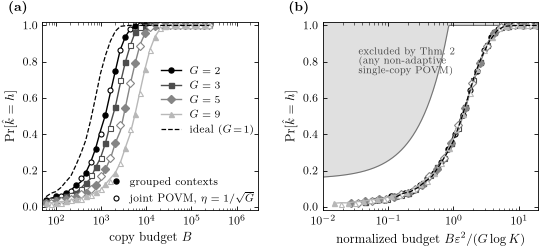

In [4]:
usetex = setup()
B = np.array(r["B"]); eps, K = r["eps"], r["K"]
GRAYS = {2: '0.0', 3: '0.30', 5: '0.52', 9: '0.72'}; MK = {2: 'o', 3: 's', 5: 'D', 9: '^'}

fig, axs = plt.subplots(1, 2, figsize=(WIDTH, 2.45)); fig.subplots_adjust(wspace=0.30)
ax = axs[0]
for G in GS:
    y = np.array(r['curves'][f'grouped_G{G}']); yj = np.array(r['curves'][f'joint_G{G}'])
    ax.plot(B, y, '-', color=GRAYS[G], marker=MK[G], markevery=2, mfc=GRAYS[G], mec=GRAYS[G], label=fr'$G={G}$')
    ax.plot(B, yj, ls='none', marker=MK[G], markevery=(1, 2), mfc='white', mec=GRAYS[G], mew=0.8)
yo = np.array(r['curves']['oracle'])
ax.plot(B, yo, '--', color='0', lw=0.9, label=r'ideal ($G\!=\!1$)')
ax.set_xscale('log'); ax.set_xlim(50, 3e6); ax.set_ylim(-0.02, 1.02)
ax.set_xlabel(r'copy budget $B$'); ax.set_ylabel(r'$\Pr[\hat k = h]$')
leg1 = ax.legend(loc='center right', ncol=1, borderaxespad=0.2, bbox_to_anchor=(1.01, 0.58), handlelength=1.9)
ax.add_artist(leg1)
h2 = [Line2D([], [], ls='none', marker='o', mfc='0', mec='0', ms=3.6),
      Line2D([], [], ls='none', marker='o', mfc='white', mec='0', mew=0.8, ms=3.6)]
ax.legend(h2, ['grouped contexts', r'joint POVM, $\eta=1/\sqrt{G}$'], loc='lower right', borderaxespad=0.2,
          handlelength=1.0, bbox_to_anchor=(1.01, 0.0))
panel(ax, 'a')

ax = axs[1]
beta = lambda Bv, G: Bv * eps ** 2 / (G * np.log(K))
bb = np.logspace(-2, 1.3, 300)
fano = np.clip(bb + np.log(2) / np.log(K), 0, 1)       # Fano bound of Theorem 2
ax.fill_between(bb, fano, 1.05, color='0.88', lw=0, zorder=0)
ax.plot(bb, fano, color='0.45', lw=0.8, zorder=1)
ax.text(0.035, 0.80, 'excluded by Thm.~2\n(any non-adaptive\nsingle-copy POVM)' if usetex else
        'excluded by Thm. 2\n(any non-adaptive\nsingle-copy POVM)', fontsize=7, color='0.25', ha='left', va='center')
for G in GS:
    ax.plot(beta(B, G), r['curves'][f'grouped_G{G}'], '-', color=GRAYS[G], marker=MK[G], markevery=2, mfc=GRAYS[G], mec=GRAYS[G])
    ax.plot(beta(B, G), r['curves'][f'joint_G{G}'], ls='none', marker=MK[G], markevery=(1, 2), mfc='white', mec=GRAYS[G], mew=0.8)
ax.plot(beta(B, 1), yo, '--', color='0', lw=0.9)
ax.set_xscale('log'); ax.set_xlim(1e-2, 2e1); ax.set_ylim(-0.02, 1.02)
ax.set_xlabel(r'normalized budget $B\varepsilon^2/(G\log K)$'); ax.set_ylabel(r'$\Pr[\hat k = h]$')
panel(ax, 'b')
fig.savefig(FIGURES / 'fig_scaling.pdf'); fig.savefig(FIGURES / 'fig_scaling.png', dpi=200)
plt.show()

## Figure 3: copies needed for success probability 0.9

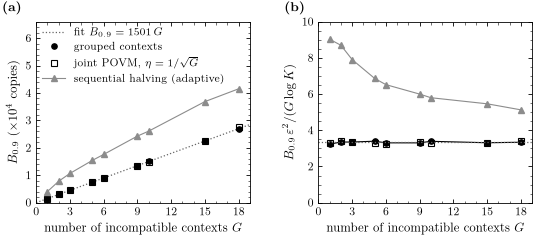

In [5]:
b = r['b90']; Gs = np.array(b['G'])
gr, jo, sh = (np.array(b[k], float) for k in ('grouped', 'joint', 'seqhalving'))
c = np.sum(gr * Gs) / np.sum(Gs ** 2)                  # least-squares fit B_0.9 = c G through the origin
norm = lambda v: v * eps ** 2 / (Gs * np.log(K))

fig, axs = plt.subplots(1, 2, figsize=(WIDTH, 2.35)); fig.subplots_adjust(wspace=0.32)
ax = axs[0]
gg = np.linspace(0, 19, 50)
ax.plot(gg, c * gg / 1e4, ':', color='0.4', lw=0.9, label=fr'fit $B_{{0.9}}={c:.0f}\,G$')
ax.plot(Gs, gr / 1e4, 'o', color='0', ms=3.8, label='grouped contexts')
ax.plot(Gs, jo / 1e4, 's', mfc='none', mec='0', mew=0.8, ms=4.6, label=r'joint POVM, $\eta=1/\sqrt{G}$')
ax.plot(Gs, sh / 1e4, '^-', color='0.55', ms=3.8, lw=0.8, label='sequential halving (adaptive)')
ax.set_xlim(0, 19); ax.set_ylim(0, 6.6)
ax.xaxis.set_major_locator(MultipleLocator(3)); ax.xaxis.set_minor_locator(MultipleLocator(1)); ax.yaxis.set_minor_locator(AutoMinorLocator())
ax.set_xlabel(r'number of incompatible contexts $G$'); ax.set_ylabel(r'$B_{0.9}$ ($\times 10^4$ copies)')
ax.legend(loc='upper left', borderaxespad=0.2)
panel(ax, 'a')
ax = axs[1]
ax.plot(Gs, norm(gr), 'o-', color='0', ms=3.8, lw=0.8)
ax.plot(Gs, norm(jo), 's', mfc='none', mec='0', mew=0.8, ms=4.6)
ax.plot(Gs, norm(sh), '^-', color='0.55', ms=3.8, lw=0.8)
ax.axhline(np.median(norm(gr)), color='0.4', ls=':', lw=0.9)
ax.set_xlim(0, 19); ax.set_ylim(0, 10)
ax.xaxis.set_major_locator(MultipleLocator(3)); ax.xaxis.set_minor_locator(MultipleLocator(1)); ax.yaxis.set_minor_locator(AutoMinorLocator())
ax.set_xlabel(r'number of incompatible contexts $G$'); ax.set_ylabel(r'$B_{0.9}\,\varepsilon^2/(G\log K)$')
panel(ax, 'b')
fig.savefig(FIGURES / 'fig_b90.pdf'); fig.savefig(FIGURES / 'fig_b90.png', dpi=200)
plt.show()

## Numbers quoted in Section 6

In [6]:
tab = pd.DataFrame({"G": Gs, "grouped": gr.astype(int), "joint": jo.astype(int), "seq. halving": sh.astype(int),
                    "norm. grouped": norm(gr), "norm. joint": norm(jo), "norm. seq. halving": norm(sh),
                    "seq. halving / grouped": sh / gr})
display(tab.style.format(precision=2))
nonad = np.concatenate([norm(gr), norm(jo)])
print(f"linear fit (grouped): B_0.9 = {c:.0f} G")
print(f"normalized cost of both non-adaptive learners: {nonad.min():.2f} to {nonad.max():.2f}")
print(f"sequential halving / grouped: {sh[0] / gr[0]:.1f} at G={Gs[0]}, {sh[-1] / gr[-1]:.1f} at G={Gs[-1]}")

,G,grouped,joint,seq. halving,norm. grouped,norm. joint,norm. seq. halving,seq. halving / grouped
0,1,1456,1491,4064,3.24,3.31,9.03,2.79
1,2,3015,3088,7828,3.35,3.43,8.70,2.60
2,3,4525,4525,10673,3.35,3.35,7.91,2.36
3,5,7643,7463,15447,3.40,3.32,6.87,2.02
4,6,8926,8820,17610,3.31,3.27,6.52,1.97
5,9,13387,13547,24299,3.31,3.35,6.00,1.82
6,10,15263,14903,26100,3.39,3.31,5.80,1.71
7,15,22353,22353,36878,3.31,3.31,5.46,1.65
8,18,27050,27703,41547,3.34,3.42,5.13,1.54


linear fit (grouped): B_0.9 = 1501 G
normalized cost of both non-adaptive learners: 3.24 to 3.43
sequential halving / grouped: 2.8 at G=1, 1.5 at G=18
